# The IFRS 9 validation battery across six reporting dates

**Question:** Does the IFRS 9 model of a small-business lender pass the validation battery of the supervisors, on which tests and on which of six reporting dates does it fail, and what can a validator conclude when a test cannot be evaluated?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- list the tests of the IFRS 9 battery, what each one asks and which supervisory expectation it comes from;
- read the lifetime PD back-test by origination cohort and by decile, and say what the engine's light means and what it does not;
- read the SICR effectiveness, the threshold stability, the stage migration and the ECL back-test, recompute the ones whose inputs the artifact keeps, and name the ones it does not;
- say what a validator concludes when a test is not evaluable, and why that is not a pass;
- compare the battery across a crisis, a recovery, a calm period and the pandemic shock on one portfolio.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
COLOR = {"green": "#2e8b57", "amber": "#e6a117", "red": "#c0392b", "not_evaluated": "#b0b0b0"}
TEST_NAME = {
    "lifetime_pd_backtest": "lifetime PD back-test",
    "sicr_effectiveness": "SICR effectiveness",
    "sicr_threshold_stability": "SICR threshold stability",
    "stage_migration_backtest": "stage migration back-test",
    "ecl_backtest": "ECL back-test",
    "scenario_sensitivity": "scenario sensitivity",
    "nonlinearity": "non-linearity",
    "overlay_diagnostics": "overlay diagnostics",
    "reconciliation_identities": "reconciliation identities",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the six reporting dates of case C06 (SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`): 2006-12-31 (before the crisis), 2008-12-31 and 2010-12-31 (the crisis and the recovery), 2019-12-31 (a calm year), 2020-06-30 (the pandemic shock) and 2023-06-30. Each file `data/derived/C06/rd-<date>.json` holds the battery's rows in `tests` and the inputs the pipeline kept in `outputs`: the lifetime back-test by origination cohort (`lifetime_backtest`), the calibration by decile (`decile_calibration`), the stage summary and the weighted and single-scenario ECL.

A `tests` row is the engine's `TestResult` as the pipeline committed it: the test identifier, the model (the rung of notebook 07: `L0-km`, `L1-dth` or `L2-cox`), the segment (an origination cohort for the lifetime test), the metric or p-value, the light, and the `extras`. Each test is a Contraste **internal gate**, not a regulatory threshold, and every row records the parameters it used in `policy_version`.

The notebook prints the engine version that baked the files beside the version installed now, and it recomputes only the tests whose inputs are in the file.

In [2]:
# Load the six reporting dates and index the portfolio-level row of each test
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DATES = ("2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06")
DERIVED = ROOT / "data" / "derived" / "C06"
cases = {d: json.loads((DERIVED / f"rd-{d}.json").read_text(encoding="utf-8")) for d in DATES}
tests = {d: {} for d in DATES}
for d, case in cases.items():
    for t in case["tests"]:
        if t["segment"] in (None, "all") and t["model_id"] == "L1-dth":
            tests[d].setdefault(t["test_id"], t)
baked = sorted({c["provenance"]["riskvalidation_version"] for c in cases.values()})
print("engine that baked the six artifacts:", *baked, "| engine installed now:", md.version("riskvalidation"))
print("test rows per date:", len(cases["2008-12"]["tests"]), "| distinct tests:", len(tests["2008-12"]))

engine that baked the six artifacts: 1.0.1 | engine installed now: 1.0.1
test rows per date: 29 | distinct tests: 9


## Method

The battery follows the validation expectations the research distilled from the supervisors (EBA/Rep/2023/36 paragraphs 94 to 118; EBA/Rep/2021/35; BCBS d350 paragraphs 36 and 50 and 51; IFRS 9 B5.5.52). Each test below is one engine function that returns one `TestResult`.

| Test | What it asks | Source |
|---|---|---|
| `lifetime_pd_backtest` | does the observed cumulative default rate stay near the predicted cumulative PD at every horizon | EBA/Rep/2023/36, paragraphs 114 to 118 |
| `sicr_effectiveness` | does the Stage 2 flag select the accounts that default | EBA/Rep/2023/36, paragraphs 94 to 99; d350 A38 |
| `sicr_threshold_stability` | does the threshold loosen when conditions worsen | EBA/Rep/2023/36, paragraphs 29 to 33 |
| `stage_migration_backtest` | are the observed stage transitions drawn from the predicted matrix | EBA/Rep/2023/36, paragraph 97 |
| `ecl_backtest` | do the discounted realised losses equal the ECL, like for like and without overlays | IFRS 9 B5.5.52; EBA/Rep/2023/36, paragraphs 100 to 104 |
| `scenario_sensitivity`, `nonlinearity` | notebook 03 | d350 paragraph 36(a) |
| `overlay_diagnostics`, `reconciliation_identities` | notebook 04 | d350 paragraphs 50 and 51; IFRS 7 35H and 35I |

Four statistics carry the notebook. The ECL back-test ratio is $R_H = \sum \mathrm{realised}/\sum \mathrm{ECL}$, green when it lies in $[0.8, 1.25]$, amber in $[0.5, 2.0]$ outside that and red beyond (the engine's defaults). The SICR effectiveness metric is the ratio of the default rates $DR_{S2}/DR_{S1}$, green from 2, amber from 1, red below. The lifetime back-test metric is the largest $|\mathrm{observed} - \mathrm{predicted}|$ over the horizons, and its light, when the asset correlation $\rho$ is given, is read against the Vasicek band of the default count among the obligors at risk (Vasicek 2002; the engine's band is central at the amber and red levels $\alpha$). The stage migration statistic is the Pearson chi-square over the rows with observations (Anderson and Goodman, 1957, equation 3.1):

$$\chi^2 = \sum_{i}\sum_{j \mid p_{ij}>0} \frac{(O_{ij} - n_i\,p_{ij})^2}{n_i\,p_{ij}}, \qquad \mathrm{df} = \sum_i (\#\{j : p_{ij} > 0\} - 1)$$

An observation in a cell predicted at zero is impossible under the null: the statistic is infinite, the p-value 0 and the light red.

A test that cannot be evaluated returns the light `not_evaluated` with its reason and an undefined statistic, never a number made up. A validator reads it as the absence of a result.

### Step 1: the battery on six dates

The first view is the whole battery. For each date, the cell takes the portfolio-level row of each of the nine tests (for the lifetime test, the `all` cohort of the `L1-dth` rung), counts the lights and draws them as a grid: one row per test, one column per date, green, amber, red, or grey for a test that was not evaluated. The grid is the committed result of the pipeline's battery; the steps that follow recompute the tests whose inputs the files keep and read the rest.

green : 34 of 54 cells
amber : 7 of 54 cells
red : 11 of 54 cells
not evaluated : 2 of 54 cells


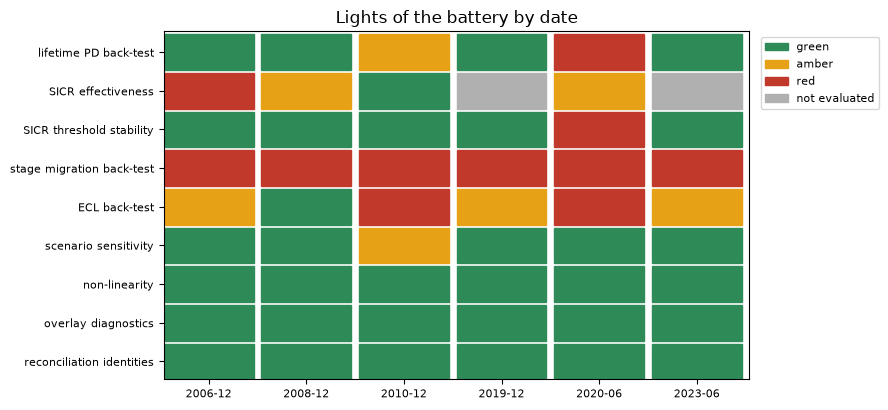

In [3]:
# Count the lights of the battery and draw them as a grid of tests by date
lights = {tid: [tests[d]["ifrs9." + tid]["light"] for d in DATES] for tid in TEST_NAME}
total_cells = len(TEST_NAME) * len(DATES)
for light in COLOR:
    count = sum(row.count(light) for row in lights.values())
    print(LIGHT[light], ":", count, "of", total_cells, "cells")

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (tid, row) in enumerate(lights.items()):
    for j, light in enumerate(row):
        ax.add_patch(plt.Rectangle((j, len(lights) - 1 - i), 0.92, 0.92, color=COLOR[light]))
ax.set_xlim(0, len(DATES))
ax.set_ylim(0, len(lights))
ax.set_xticks(np.arange(len(DATES)) + 0.46)
ax.set_xticklabels(DATES, fontsize=8)
ax.set_yticks(np.arange(len(lights)) + 0.46)
ax.set_yticklabels([TEST_NAME[t] for t in reversed(list(lights))], fontsize=8)
ax.legend(handles=[Patch(color=COLOR[k], label=LIGHT[k]) for k in COLOR], fontsize=8, loc="upper left",
          bbox_to_anchor=(1.01, 1.0))
ax.set_title("Lights of the battery by date")
fig.tight_layout()
plt.show()

Of the 54 cells (nine tests, six dates) 34 are green, 7 amber, 11 red and 2 not evaluated. Three tests are green on every date: the non-linearity, the overlay diagnostics and the reconciliation identities, which check the engine's arithmetic and the tables of notebooks 03 and 04. The stage migration test is red on every date. The informative rows are the others: the lifetime back-test turns red on 2020-06, the SICR effectiveness is red in 2006 and amber in 2008 and 2020-06, and the ECL back-test is green only in 2008.

### Step 2: the lifetime PD back-test

The lifetime test compares the cumulative PD the model predicts for an origination cohort at 6, 12, ..., 36 months with the observed cumulative default rate (a Kaplan-Meier estimate), and reads the largest gap. The artifact keeps the predicted and observed curves of the `all` cohort and, in the committed row, the Vasicek band around the prediction. The cell calls the engine's `lifetime_pd_backtest` on those curves without the asset correlation, which makes it use the relative-gap rule, and sets that light beside the committed light, which used the band. The figure draws the two curves and the band.

largest gap: 0.01669
largest relative gap: 0.3228
light without the correlation: amber
light with the correlation (the committed row): green
horizons inside the band: 6 of 6


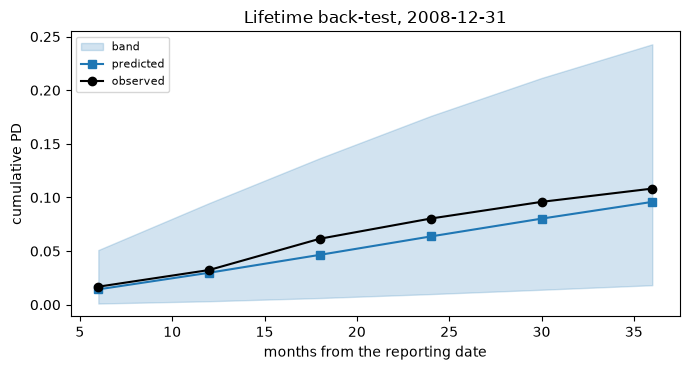

In [4]:
# Recompute the lifetime back-test of the 2008 portfolio with the engine and draw it against its band
rows = [r for r in cases["2008-12"]["outputs"]["lifetime_backtest"]["rows"] if r["origination_cohort"] == "all"]
stored_row = tests["2008-12"]["ifrs9.lifetime_pd_backtest"]
months = np.array([r["months"] for r in rows])
pred = np.array([r["predicted_cumulative_pd"] for r in rows])
obs = np.array([r["observed_cumulative_pd"] for r in rows])
low, high = np.array(stored_row["extras"]["band_low"]), np.array(stored_row["extras"]["band_high"])
n_at_risk = np.full(months.size, stored_row["n"], dtype=float)
n_events = np.full(months.size, stored_row["n_events"], dtype=float)
result = ifrs9.lifetime_pd_backtest(months, pred, obs, n_at_risk, n_events, model_id="L1-dth", segment="all")
print("largest gap:", round(result.metric, 6))
print("largest relative gap:", round(max(result.extras["relative_gap"]), 4))
print("light without the correlation:", LIGHT[result.light.value])
print("light with the correlation (the committed row):", LIGHT[stored_row["light"]])
print("horizons inside the band:", int(np.sum((obs >= low) & (obs <= high))), "of", months.size)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.fill_between(months, low, high, color="tab:blue", alpha=0.2, label="band")
ax.plot(months, pred, color="tab:blue", marker="s", label="predicted")
ax.plot(months, obs, color="black", marker="o", label="observed")
ax.set_xlabel("months from the reporting date")
ax.set_ylabel("cumulative PD")
ax.set_title("Lifetime back-test, 2008-12-31")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

On the 2008 portfolio the largest gap between the predicted and the observed cumulative PD is 0.01669, and the observed curve lies inside the Vasicek band at all 6 of 6 horizons, so the committed light, which uses the band, is green. The call without the asset correlation uses the relative-gap rule, whose largest relative gap is 0.3228, and gives amber. Neither is wrong: the band says the gap is compatible with the correlation of defaults the policy assumes, and the relative rule says the 36-month prediction is a third off. The observed curve sits above the prediction at every horizon, so the model under-predicts mildly, and a validator reports the rule together with the light.

### Step 3: by origination cohort and by decile

The same test run on each origination cohort asks whether the model is calibrated for the loans of every year and not only on average. The cell tabulates the largest gap of each cohort for the three rungs of notebook 07, and reads the calibration by decile of predicted PD at 12 months. The figure draws the observed against the predicted cumulative PD of the ten deciles, with the line of perfect calibration, and the largest gap of the `L1-dth` rung by cohort, coloured by the committed light.

cohort    L0-km   L1-dth   L2-cox
older    0.0028   0.0015   0.0096
2004     0.0286   0.0349   0.0177
2005     0.0379   0.0575   0.0330
2006     0.0055   0.0359   0.0031
2007     0.1240   0.0859   0.1163
2008     0.0847   0.0445   0.0817
all      0.0427   0.0167   0.0427
ratio observed over predicted by decile, 12 months: [0.97 1.53 1.91 2.04 2.14 1.31 1.18 0.82 0.5  0.77]


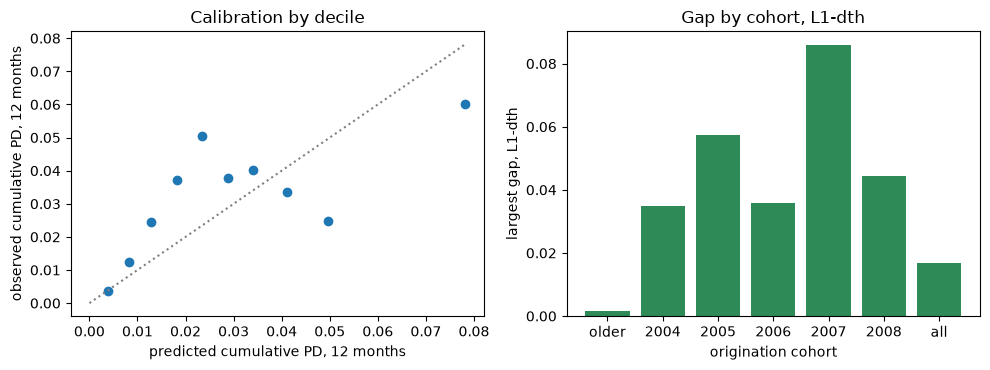

In [5]:
# Tabulate the lifetime test by cohort and rung, and the calibration by decile, and draw them
c08 = cases["2008-12"]
by = {(t["model_id"], t["segment"]): t for t in c08["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}
cohorts = ["older", "2004", "2005", "2006", "2007", "2008", "all"]
rungs = ("L0-km", "L1-dth", "L2-cox")
print("cohort", *[f"{r:>8s}" for r in rungs])
for cohort in cohorts:
    print(f"{cohort:6s}", *[f"{by[(r, cohort)]['metric']:8.4f}" for r in rungs])
deciles = [r for r in c08["outputs"]["decile_calibration"]["rows"] if r["months"] == 12]
predicted = np.array([r["predicted_cumulative_pd"] for r in deciles])
observed = np.array([r["observed_cumulative_pd"] for r in deciles])
print("ratio observed over predicted by decile, 12 months:", np.round(observed / predicted, 2))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.scatter(predicted, observed, color="tab:blue")
left.plot([0, predicted.max()], [0, predicted.max()], color="grey", linestyle=":")
left.set_xlabel("predicted cumulative PD, 12 months")
left.set_ylabel("observed cumulative PD, 12 months")
left.set_title("Calibration by decile")
metrics = [by[("L1-dth", c)]["metric"] for c in cohorts]
right.bar(cohorts, metrics, color=[COLOR[by[("L1-dth", c)]["light"]] for c in cohorts])
right.set_xlabel("origination cohort")
right.set_ylabel("largest gap, L1-dth")
right.set_title("Gap by cohort, L1-dth")
fig.tight_layout()
plt.show()

The pooled result hides the cohorts. The 2007 cohort is amber for the Kaplan-Meier rung (0.1240) and the Cox rung (0.1163) and green for the discrete-time rung (0.0859); the 2008 cohort is amber for the Cox rung; on the pooled `all` cohort the three rungs are green with gaps of 0.0427, 0.0167 and 0.0427. The decile calibration on the left is not monotone: the observed-to-predicted ratio is 0.97 in decile 1, rises to 2.14 in decile 5 and falls to 0.50 in decile 9 and 0.77 in decile 10. The loans the model calls riskiest default less than predicted and the middle ones more, so the rank order of the prediction is only loosely the order of the outcomes.

### Step 4: does Stage 2 select the defaulters? (SICR effectiveness)

If the staging works, the accounts in Stage 2 at the reporting date should default more often in the following year than the accounts in Stage 1. The metric is the ratio of the two default rates, $DR_{S2}/DR_{S1}$, green from 2, amber from 1 and red below; the area under the ROC curve of the stage as a classifier is read beside it. The committed rows hold the counts of each date, which the engine's test needs at account level and the artifact does not keep, so the cell reads them. The figure draws the two default rates by date.

2006-12 red | DR2/DR1: 0.9662
   area under the ROC curve: 0.4999
2008-12 amber | DR2/DR1: 2.2525
   area under the ROC curve: 0.5256
2010-12 green | DR2/DR1: 2.4376
   area under the ROC curve: 0.5783
2019-12 not evaluated | accounts: 271801 | Stage 2 accounts: 0
2020-06 amber | DR2/DR1: 1.9951
   area under the ROC curve: 0.5085
2023-06 not evaluated | accounts: 251636 | Stage 2 accounts: 0


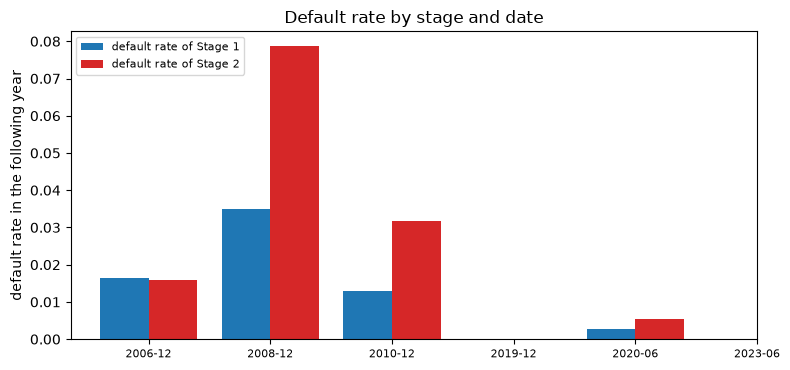

In [6]:
# Read the SICR effectiveness of each date from the committed rows and draw the default rates
dr1, dr2 = [], []
for d in DATES:
    row = tests[d]["ifrs9.sicr_effectiveness"]
    x = row["extras"]
    if row["light"] == "not_evaluated":
        stage2 = [r["accounts"] for r in cases[d]["outputs"]["stage_summary"]["rows"] if r["stage"] == "stage2"]
        print(d, LIGHT[row["light"]], "| accounts:", row["n"], "| Stage 2 accounts:", sum(stage2))
        dr1.append(float("nan"))
        dr2.append(float("nan"))
        continue
    dr1.append(x["default_rate_stage1"])
    dr2.append(x["default_rate_stage2"])
    print(d, LIGHT[row["light"]], "| DR2/DR1:", round(row["metric"], 4))
    print("   area under the ROC curve:", round(x["roc_auc"], 4))

fig, ax = plt.subplots(figsize=(8, 3.8))
x_pos = np.arange(len(DATES))
ax.bar(x_pos - 0.2, dr1, width=0.4, color="tab:blue", label="default rate of Stage 1")
ax.bar(x_pos + 0.2, dr2, width=0.4, color="tab:red", label="default rate of Stage 2")
ax.set_xticks(x_pos)
ax.set_xticklabels(DATES, fontsize=8)
ax.set_ylabel("default rate in the following year")
ax.set_title("Default rate by stage and date")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The effectiveness of the staging changes with the date. The ratio of the default rate of Stage 2 to that of Stage 1 is 0.9662 in 2006, red: Stage 2 defaulted slightly less than Stage 1 and the area under the ROC curve is 0.4999, no better than a coin. It is 2.2525 in 2008 (amber), 2.4376 in 2010 (green) and 1.9951 in 2020-06 (amber, just under the green cut-off of 2). On 2019-12 and 2023-06 there is no Stage 2 account, the bars are missing and the test cannot be evaluated. Where it can, the area under the curve stays between 0.4999 and 0.5783, a weak classifier.

### Step 5: the threshold must not loosen when conditions worsen

`sicr_threshold_stability` counts the reporting periods in which the implied SICR multiplier rises while a condition index rises too: loosening the threshold exactly when conditions get worse. The artifact keeps the committed count of each date, and the engine's function runs on any pair of series, so the cell calls it on three constructed ones, a multiplier that falls as conditions worsen, one that loosens twice and one that rises with every worsening, and prints the committed counts beside them.

In [7]:
# Run the threshold stability test on three constructed series and read the committed rows
condition = np.array([1.0, 2.0, 3.0, 2.5, 4.0, 5.0])
series = {
    "multiplier falls as conditions worsen": np.array([3.0, 2.8, 2.6, 2.6, 2.4, 2.2]),
    "two periods loosen": np.array([2.0, 2.0, 2.5, 2.5, 3.0, 3.0]),
    "the multiplier rises with every worsening": np.array([2.0, 2.2, 2.5, 2.5, 2.8, 3.1]),
}
for label, multiplier in series.items():
    r = ifrs9.sicr_threshold_stability(multiplier, condition)
    print(f"{label:48s}", LIGHT[r.light.value], "| count:", int(r.metric))
for d in DATES:
    x = tests[d]["ifrs9.sicr_threshold_stability"]["extras"]
    light = tests[d]["ifrs9.sicr_threshold_stability"]["light"]
    print(d, LIGHT[light], "| periods that loosen:", len(x["loosening_periods"]), "of", x["periods"])

multiplier falls as conditions worsen            green | count: 0
two periods loosen                               amber | count: 2
the multiplier rises with every worsening        red | count: 4
2006-12 green | periods that loosen: 0 of 2
2008-12 green | periods that loosen: 0 of 2
2010-12 green | periods that loosen: 0 of 2
2019-12 green | periods that loosen: 0 of 2
2020-06 red | periods that loosen: 1 of 2
2023-06 green | periods that loosen: 0 of 2


Only 2020-06 is red: one of its two periods loosens, which is half, and every other date has none. On the constructed series the engine gives green for a multiplier that falls as conditions worsen, amber for two loosening periods and red for four. The test reads the direction of the threshold and nothing else: it says that the threshold was not relaxed exactly when conditions got worse, and it is blind to the level of the multiplier, which notebook 02 showed to be the lever that decides how many loans move to Stage 2.

### Step 6: the stage migration back-test

`stage_migration_backtest` compares a predicted 3 by 3 matrix of one-year stage transitions with the observed counts through the chi-square above. The committed rows are red on every date, and the cell prints why: the degrees of freedom, the rows skipped and whether an observation fell in a cell the prediction assigns zero. It then runs the engine's function on three constructed matrices, one with counts near the prediction, one with a single count in a cell predicted at zero and one with counts that moved a lot.

In [8]:
# Run the migration test on three constructed matrices and read the committed rows
for d in DATES:
    row = tests[d]["ifrs9.stage_migration_backtest"]
    x = row["extras"]
    print(d, LIGHT[row["light"]], "| accounts compared:", row["n"])
    print("   degrees of freedom:", x["degrees_of_freedom"])
    impossible = "yes" if x["impossible_cell_observed"] else "no"
    print("   rows skipped:", x["rows_skipped"], "| impossible cell observed:", impossible)

predicted_matrix = np.array([[0.90, 0.08, 0.02], [0.20, 0.70, 0.10], [0.00, 0.00, 1.00]])
cases_built = {
    "counts near the prediction": np.array([[905, 75, 20], [21, 68, 11], [0, 0, 10]]),
    "a count in a cell predicted at zero": np.array([[900, 80, 20], [20, 70, 10], [1, 0, 9]]),
    "counts that moved a lot": np.array([[800, 150, 50], [40, 50, 10], [0, 0, 10]]),
}
for label, counts in cases_built.items():
    r = ifrs9.stage_migration_backtest(predicted_matrix, counts, model_id="lesson")
    statistic = round(r.statistic, 3) if math.isfinite(r.statistic) else "infinite"
    print(f"{label:44s}", LIGHT[r.light.value], "| statistic:", statistic, "| p-value:", round(r.p_value, 4))

2006-12 red | accounts compared: 225212
   degrees of freedom: 1
   rows skipped: 2 | impossible cell observed: yes
2008-12 red | accounts compared: 273225
   degrees of freedom: 1
   rows skipped: 2 | impossible cell observed: yes
2010-12 red | accounts compared: 248757
   degrees of freedom: 4
   rows skipped: 1 | impossible cell observed: no
2019-12 red | accounts compared: 229819
   degrees of freedom: 1
   rows skipped: 2 | impossible cell observed: no
2020-06 red | accounts compared: 232633
   degrees of freedom: 1
   rows skipped: 2 | impossible cell observed: yes
2023-06 red | accounts compared: 205785
   degrees of freedom: 1
   rows skipped: 2 | impossible cell observed: no
counts near the prediction                   green | statistic: 0.547 | p-value: 0.9687
a count in a cell predicted at zero          red | statistic: infinite | p-value: 0.0
counts that moved a lot                      red | statistic: 143.075 | p-value: 0.0


The committed migration test is red on all six dates, and the reason is in the matrix and not in a lack of data. In 2006, 2008 and 2020-06 an observation falls in a cell that the predicted matrix assigns zero, so the statistic is infinite; on the other dates the statistic is large enough for the p-value to be zero to many digits. On the constructed matrices the engine behaves as designed: counts near the prediction give a statistic of 0.547 and a p-value of 0.9687, a single count in a cell predicted at zero gives an infinite statistic, and counts that moved a lot give 143.075. The test works, and the predicted matrix is the thing to review, in line with finding `F-MIGRATION-red`.

### Step 7: the ECL back-test, recomputed

The ECL back-test needs two numbers: the sum of the discounted losses realised in the 12 months after the reporting date and the sum of the 12-month ECL of the same accounts. The artifact keeps both for each date, so the cell recomputes $R_H$ and its light with the engine's `ecl_backtest`. The figure draws $R_H$ by date on a logarithmic axis, with the green band $[0.8, 1.25]$ and the amber band $[0.5, 2.0]$ behind it.

2006-12 | realised, USD millions: 342.8
   ECL, USD millions: 457.3
   R_H: 0.7496 amber
2008-12 | realised, USD millions: 879.1
   ECL, USD millions: 840.5
   R_H: 1.046 green
2010-12 | realised, USD millions: 819.5
   ECL, USD millions: 1752.0
   R_H: 0.4678 red
2019-12 | realised, USD millions: 325.7
   ECL, USD millions: 579.6
   R_H: 0.5619 amber
2020-06 | realised, USD millions: 313.1
   ECL, USD millions: 4393.5
   R_H: 0.0713 red
2023-06 | realised, USD millions: 496.0
   ECL, USD millions: 777.6
   R_H: 0.6378 amber


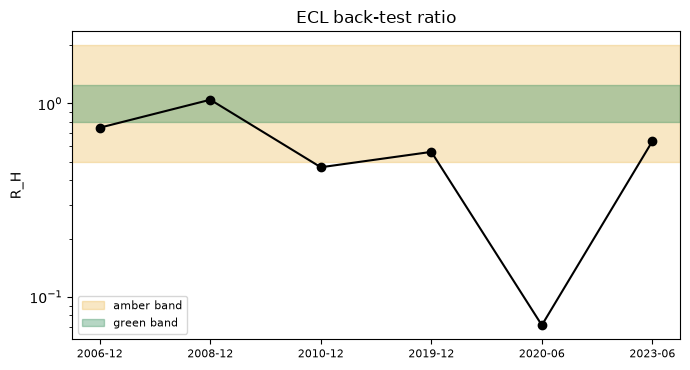

In [9]:
# Recompute the ECL back-test ratio of each date from its two sums and draw it
r_values = []
for d in DATES:
    x = tests[d]["ifrs9.ecl_backtest"]["extras"]
    realised, expected = np.array([x["sum_realised"]]), np.array([x["sum_ecl"]])
    r = ifrs9.ecl_backtest(realised, expected, x["horizon_months"], model_id="L1-dth")
    r_values.append(r.metric)
    print(d, "| realised, USD millions:", round(x["sum_realised"] / 1e6, 1))
    print("   ECL, USD millions:", round(x["sum_ecl"] / 1e6, 1))
    print("   R_H:", round(r.metric, 4), LIGHT[r.light.value])

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axhspan(0.5, 2.0, color="#e6a117", alpha=0.25, label="amber band")
ax.axhspan(0.8, 1.25, color="#2e8b57", alpha=0.35, label="green band")
ax.plot(range(len(DATES)), r_values, marker="o", color="black")
ax.set_yscale("log")
ax.set_xticks(range(len(DATES)))
ax.set_xticklabels(DATES, fontsize=8)
ax.set_ylabel("R_H")
ax.set_title("ECL back-test ratio")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The ratio $R_H$ is 0.7496, 1.046, 0.4678, 0.5619, 0.0713 and 0.6378 over the six dates, and only 2008 lies inside the green band of the figure. On five of the six dates the allowance exceeds the loss realised in the following year. On 2020-06 the realised discounted loss is 313.1 million USD against an ECL of 4,393.5 million, a ratio of 0.0713 far below the amber band, and the light is red. A validator reads that as a question and not as a verdict: either the ECL anticipated a loss that did not come, or the realised losses of the year are not all recorded yet.

### Step 8: scenario sensitivity, recomputed

`scenario_sensitivity` needs the ECL at 100% of each scenario, the weights and the ECL at the mean path, as notebook 03 used them. The artifact keeps all three for each date, so the cell recomputes the non-linearity index and its light for every date, and asks whether the ECL rises with the severity of the scenario, which is the order a sensitivity assumes.

In [10]:
# Recompute the scenario sensitivity of each date from its single-scenario ECL
for d in DATES:
    x = tests[d]["ifrs9.scenario_sensitivity"]["extras"]
    weights = np.array([s["weight"] for s in cases[d]["outputs"]["scenarios"]])
    single = np.array(x["single_scenario_ecl"])
    r = ifrs9.scenario_sensitivity(single, weights, x["ecl_at_mean_path"], model_id="L1-dth")
    ordered = bool(np.all(np.diff(single) >= 0))
    print(d, "| NL:", round(r.metric, 5), LIGHT[r.light.value])
    print("   ECL rises with the severity of the scenario:", "yes" if ordered else "no")

2006-12 | NL: 0.00211 green
   ECL rises with the severity of the scenario: no
2008-12 | NL: 0.02121 green
   ECL rises with the severity of the scenario: no
2010-12 | NL: -0.00071 amber
   ECL rises with the severity of the scenario: yes
2019-12 | NL: 0.0232 green
   ECL rises with the severity of the scenario: yes
2020-06 | NL: 0.01279 green
   ECL rises with the severity of the scenario: no
2023-06 | NL: 0.00622 green
   ECL rises with the severity of the scenario: yes


The index is 0.00211, 0.02121, -0.00071, 0.0232, 0.01279 and 0.00622 over the six dates, green everywhere except 2010-12, where the light is amber because the index is negative: a weighted ECL below the ECL at the mean path is unexpected for a convex loss. The ECL rises with the severity of the scenario only on 2010-12, 2019-12 and 2023-06. On 2006-12, 2008-12 and 2020-06 it does not, and those are the dates carrying the finding `F-SCENARIO-ORDER`, so a sensitivity built on the order of the scenarios is read with that finding beside it.

### Step 9: what a validator concludes when a test is not evaluable

On 2019-12-31 and 2023-06-30 there is no Stage 2 account, so the default rate of Stage 2 does not exist and `sicr_effectiveness` returns `not_evaluated` with an undefined metric. The cell reproduces the two ways a sample can make the test impossible with constructed data and a seeded generator: a sample with no Stage 2 account and a sample with Stage 2 accounts but no default in Stage 1. It then lists the dates of the committed rows that are not evaluated.

In [11]:
# Run the effectiveness test on constructed samples where it cannot be evaluated
rng = np.random.default_rng(7)
n = 200
defaulted = rng.random(n) < 0.05
months_in_s2 = np.where(defaulted, 0.0, np.nan)
backstop = np.zeros(n, dtype=bool)
direct = defaulted.copy()
no_stage2 = ifrs9.sicr_effectiveness(np.ones(n), defaulted, 12, months_in_s2, direct, backstop, model_id="lesson")
print("no Stage 2 account:", LIGHT[no_stage2.light.value])
print("   metric is undefined:", "yes" if math.isnan(no_stage2.metric) else "no")

stage = np.where(np.arange(n) < 20, 2.0, 1.0)
few = np.arange(n) < 3
months_few = np.where(few, 2.0, np.nan)
never = np.zeros(n, dtype=bool)
no_default_s1 = ifrs9.sicr_effectiveness(stage, few, 12, months_few, never, backstop, model_id="lesson")
print("no default in Stage 1:", LIGHT[no_default_s1.light.value])
print("   metric is undefined:", "yes" if math.isnan(no_default_s1.metric) else "no")
missing = [d for d in DATES if tests[d]["ifrs9.sicr_effectiveness"]["light"] == "not_evaluated"]
print("dates not evaluated in the committed rows:", missing)

no Stage 2 account: not evaluated
   metric is undefined: yes
no default in Stage 1: not evaluated
   metric is undefined: yes
dates not evaluated in the committed rows: ['2019-12', '2023-06']


Both constructed samples return a light of not evaluated with an undefined metric and not a number: with no Stage 2 account there is no default rate of Stage 2, and with no default in Stage 1 the ratio has a zero denominator. The committed rows say the same for 2019-12 and 2023-06. A validator reads a test that is not evaluated as the absence of a result. The report must say that the staging was not tested on those dates, and it must not count them among the tests that passed.

## Results

**Answer:** No: of the 54 cells of the battery (nine tests on six dates) 34 are green, 7 amber, 11 red and 2 not evaluated, and the model fails where a validator looks first: the stage migration test is red on all six dates, the ECL back-test ratio lies in the green band only in 2008 (1.046) and falls to 0.0713 in 2020-06, and the SICR effectiveness ratio is 0.9662 in 2006 and cannot be computed on 2019-12 and 2023-06, where no loan is in Stage 2, which a report must state as untested and never as passed.

- **The battery in one grid.** Three tests are green on every date: the non-linearity, the overlay diagnostics and the reconciliation identities, which check the engine's arithmetic and the tables (notebooks 03 and 04). The stage migration test is red on every date. The informative rows are the others.
- **The lifetime PD test depends on its rule.** In 2008 the largest gap on the `all` cohort is 0.01669 and the observed curve lies inside the committed band at the 6 of 6 horizons, so the committed light is green. The call without the asset correlation uses the relative-gap rule, whose largest relative gap is 0.3228, and gives amber. A validator reports the rule with the light.
- **The pooled result hides the cohorts.** The 2007 cohort is amber for the Kaplan-Meier rung (0.1240) and the Cox rung (0.1163) and green for the discrete-time rung (0.0859). The decile calibration is not monotone: the observed-to-predicted ratio is 0.97 in decile 1, 2.14 in decile 5 and 0.50 in decile 9.
- **SICR effectiveness changes with the date.** The ratio of the default rates is 0.9662 in 2006 (red), 2.2525 in 2008 (amber), 2.4376 in 2010 (green) and 1.9951 in 2020-06 (amber), with an area under the ROC curve between 0.4999 and 0.5783.
- **The threshold stability test fires once.** Only 2020-06 is red, with one of two periods loosening. On constructed series the engine gives green for none, amber for two loosening periods and red for four.
- **The stage migration test is red everywhere, for a reason a validator must read.** In 2006, 2008 and 2020-06 an observation falls in a cell the predicted matrix assigns zero. The constructed cases show both sides: counts near the prediction give a statistic of 0.547 and a p-value of 0.9687, and counts that moved give 143.075.
- **The ECL back-test says the allowance was above the realised loss on five of six dates.** $R_H$ is 0.7496, 1.046, 0.4678, 0.5619, 0.0713 and 0.6378, and only 2008 is green. In 2020-06 the realised discounted loss is 313.1 million USD against an ECL of 4,393.5 million.
- **The scenario sensitivity** shows that the ECL rises with the severity of the scenario on 2010-12, 2019-12 and 2023-06 and does not on 2006-12, 2008-12 and 2020-06, the dates carrying the finding `F-SCENARIO-ORDER`. In 2010-12 the index is negative ($-0.00071$), amber.
- **A test that cannot be evaluated is not a pass.** On 2019-12 and 2023-06 there is no Stage 2 account, so the effectiveness test returns not evaluated with an undefined metric.

What this notebook does not show: the lights are Contraste's internal gates, not regulatory thresholds, and the observed outcomes are charge-offs of SBA loans, not defaults of a mortgage book. The tests whose account-level inputs the artifacts do not keep (the effectiveness and the migration of the committed dates) are read from their rows and exercised on constructed data.

## Summary

- The IFRS 9 battery has nine tests, each one engine function returning one `TestResult`, each an internal gate with its parameters recorded in the row.
- Recompute what the artifact's inputs allow (the lifetime metric, the ECL back-test, the scenario sensitivity) and read the rest as committed rows, exercising the engine on constructed data where the inputs are not kept.
- A light depends on its rule: the lifetime test is green with the Vasicek band and amber with the relative gap on the same numbers, so a report states the rule.
- The pooled result hides cohorts and deciles; the effectiveness of the staging changes with the date and is not evaluable when there is no Stage 2.
- A test that cannot be evaluated is the absence of a result; the stage migration test is red on every date and the reason is in its rows.

**What to try next.** Open the Kaplan-Meier and Cox rows of 2008 and compare their cohort gaps with the discrete-time rung; change the constructed `predicted_matrix` of step 6 so that the zero cell is small but positive. Then continue with notebook 06, which provisions one bank under three regimes.

## References

- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- EBA (2021), IFRS 9 implementation by EU institutions, monitoring report, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equation (3.1). https://doi.org/10.1214/aoms/1177707039
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf